In [37]:
!pip install pandas
!pip install plotly
!pip install sqlite3
!pip install statsmodels
!pip install scikit-learn
!pip install matplotlib
# Import libraries
import sqlite3
import pandas as pd
import plotly.express as px
import plotly.io as pio
import numpy as np
import statsmodels.api as sm
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
from matplotlib.colors import ListedColormap
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import AdaBoostRegressor, RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error, r2_score
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (12, 8)



Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


ERROR: Could not find a version that satisfies the requirement sqlite3 (from versions: none)
ERROR: No matching distribution found for sqlite3


Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [38]:
# 2. Connect to the database file (update filename if needed)
conn = sqlite3.connect(r"C:\Users\Admin\OneDrive\Documents\GIDEON ECON1205\NEW_ECON_1205.db")

In [39]:
# 3. Read in the tables
df_countries = pd.read_sql_query("SELECT * FROM countries", conn)
df_gdp = pd.read_sql_query("SELECT * FROM GDP", conn)
df_unemployment = pd.read_sql_query("SELECT * FROM Unemployment", conn)
df_expenditure = pd.read_sql_query("SELECT * FROM Expenditure", conn)
df_inflation = pd.read_sql_query("SELECT * FROM Inflation", conn)
df_population = pd.read_sql_query("SELECT * FROM Population", conn)
conn.close()

In [40]:
# 4. Rename the 2025 data columns to concise variable names
df_gdp = df_gdp.rename(columns={"2025 [YR2025]": "gdp"})
df_unemployment = df_unemployment.rename(columns={"2025 [YR2025]": "unemployment"})
df_population = df_population.rename(columns={"2025 [YR2025]": "population"})
df_expenditure = df_expenditure.rename(columns={"2025 [YR2025]": "expenditure"})
df_inflation = df_inflation.rename(columns={"2025 [YR2025]": "inflation"})

In [41]:
# 5. Merge indicator tables on Country Code
df = (
    df_unemployment[["Country Code", "unemployment"]]
    .merge(df_gdp[["Country Code", "gdp"]], on="Country Code", how="inner")
    .merge(df_inflation[["Country Code", "inflation"]], on="Country Code", how="inner")
    .merge(df_population[["Country Code", "population"]], on="Country Code", how="inner")
    .merge(df_expenditure[["Country Code", "expenditure"]], on="Country Code", how="inner")
)

In [42]:
# 6. Merge with the countries table to map codes to official country names
df = pd.merge(
    left=df,
    right=df_countries,
    left_on="Country Code",
    right_on="country_code",
    how="inner"
)

In [43]:
# 7. Data Cleaning: Convert '..' and strings into proper numeric values and drop NaNs
df["gdp"] = pd.to_numeric(df["gdp"], errors="coerce")
df["gdp_billion"] = df["gdp"] / 1e9  # Convert GDP to billions for better readability
df["unemployment"] = pd.to_numeric(df["unemployment"], errors="coerce")
df["population"] = pd.to_numeric(df["population"], errors="coerce")
df["population_million"] = df["population"] / 1e6  # Convert Population to millions for better readability
df["expenditure"] = pd.to_numeric(df["expenditure"], errors="coerce")
df["expenditure_billion"] = df["expenditure"] / 1e9  # Convert Expenditure to billions for better readability
df["inflation"] = pd.to_numeric(df["inflation"], errors="coerce")
df_clean = df.dropna(subset=["gdp", "unemployment", "population", "expenditure", "inflation"]).copy()

In [44]:
# 8. Interactive Plotly Scatter Plot
fig = px.scatter(
    df_clean,
    x="gdp",
    y="unemployment",
    color="country_code",
    hover_name="country_code",
    hover_data={
        "Country Code": True,
        "gdp": ":,.0f",
        "unemployment": ":.2f"
    },
    labels={
        "gdp": "GDP (constant 2015 US$)",
        "unemployment": "Unemployment (% of labor force)"
    },
    title="Unemployment Rate vs. GDP in 2025",
    log_x=True  # Log scale handles the wide skew across national GDP levels
)

In [45]:
# 9 Set the renderer to open the graph in your default web browser
pio.renderers.default = "browser"

fig.update_layout(template="plotly_white")
fig.show()

In [46]:
# 10 Plot a bar chart for all countries showing the relationship between Population, Unemployment
df_top10 = df_clean.nlargest(10, "gdp")
fig_bar = px.bar(   
    df_clean,
    x="expenditure_billion",
    y="country_code",
    color="country_code",
    hover_name="country_code",
    hover_data={
        "Country Code": True,
        "country_name": ":,.3f",
        "country_code": ":.8f"
    },
    labels={
        "expenditure_billion": "Government Expenditure (constant 2015 US$) in Billions"
    },
    title="Country vs. Government Expenditure in 2025 (Bar Chart)",
    log_x=True  # Log scale handles the wide skew across national GDP levels
)
fig_bar.show()

In [47]:
# 12 Clustering Unemployment and Inflation across the top 10 countries by GDP
df_top10 = df_clean.nlargest(10, "gdp")

fig_cluster = px.bar(
    df_top10,
    x="population_million",
    y=["unemployment", "inflation"],
    barmode="group",
    labels={
        "country_name": "Country",
        "value": "Percentage (%)",
        "variable": "Indicator"
    },
    title="Unemployment vs. Inflation Across Top 10 Economies (Clustered Bar Chart)"
)
fig_cluster.show()

In [48]:
# 13 plot a radar chart for all countries showing the relationship between Population, Unemployment, Expenditure and Inflation
# ==========================================
# CHART 4: Normalized Radar Chart (Top 5 Economies)
# ==========================================
# Min-Max normalize all indicators to [0, 1] across the full dataset
indicators = ["gdp", "expenditure", "population", "unemployment", "inflation"]
df_norm = df_clean[["country_code"] + indicators].copy()
for col in indicators:
    df_norm[col] = (df_norm[col] - df_norm[col].min()) / (df_norm[col].max() - df_norm[col].min())

# Select Top 5  developed countries by raw GDP for visual clarity
top5_countries = df_clean.nlargest(5, "gdp")["country_code"]
df_radar = df_norm[df_norm["country_code"].isin(top5_countries)].melt(
    id_vars="country_code",
    value_vars=indicators,
    var_name="Indicator",
    value_name="Normalized Score"
)

fig_radar = px.line_polar(
    df_radar,
    r="Normalized Score",
    theta="Indicator",
    color="country_code",
    line_close=True,
    range_r=[0, 1],
    title="4. Normalized Macroeconomic Profile: Top 5 Economies by GDP"
)
fig_radar.update_traces(fill="toself", opacity=0.35)
fig_radar.show()

This rader chat compares five major world bank regional and income blocs across normalized macro indicators. the chat shows that all the five blocs cluster near the origin on inflation and unemployment, reflecting cross-country macro sability 

In [ ]:
# ==========================================
# CHART 14: Bubble Scatter Plot (Multivariate Scaling)
# ==========================================
fig_bubble = px.scatter(
    df_clean,
    x="gdp",
    y="expenditure",
    size="population",
    color="unemployment",
    hover_name="country_code",
    hover_data={
        "Country Code": True,  # <-- Space instead of underscore
        "gdp": ":,.0f",
        "expenditure": ":,.0f",
        "population": ":,.0f",
        "unemployment": ":.2f",
        "inflation": ":.2f"
    },
    log_x=True,
    log_y=True,
    size_max=45,
    size_min=4,
    color_continuous_scale="Viridis",
    labels={
        "gdp": "GDP (Log Scale)",
        "expenditure": "Expenditure (Log Scale)",
        "unemployment": "Unemployment (%)",
        "population": "Population"
    },
    title="1. Expenditure vs. GDP (Sized by Population, Colored by Unemployment)"
)
fig_bubble.show()

This is a multi-dimensional Plotly bubble chart displays GDP (Log Scale) on the x-axis against expenditure(log-scale) on the y-axis, encoding population via bubble size and unemployment rate via color the result comfirm national income parity. Bubble sozes expand steadily up the digonal, showing how larger population drive greater output, meanwhile the colors reveals economies maintain moderate unemployment, whereas unemployment spikes appear exclusively among smaller countries. 


In [50]:
# ==========================================
# CHART 15: Correlation Matrix Heatmap
# ==========================================
indicators = ["gdp", "expenditure", "population", "unemployment", "inflation"]

corr_matrix = df_clean[indicators].corr(method="pearson").round(2)

fig_corr = px.imshow(
    corr_matrix,
    text_auto=True,
    aspect="auto",
    color_continuous_scale="RdBu_r",
    zmin=-1,
    zmax=1,
    title="2. Pearson Correlation Matrix Across Macroeconomic Indicators"
)
fig_corr.show()

The correlation heat map use the pearson correlation matrix and the result reveals a sharp structural split between scale-dependant macroeconomi aggregates and rate-based cyclical indicators across the data base. It also show a strong positive scale cluster(GDP, Ependiture, Population) and also a weak cross-sectional correlation among rate variables (unemployment and inflation)

In [51]:
# Marginal Distribution Scatter Plot
fig_marg = px.scatter(
    df_clean,
    x="expenditure",
    y="gdp",
    hover_name="country_code",
    trendline="ols",
    marginal_x="box",
    marginal_y="histogram",
    title="GDP vs Expenditure with OLS Fit & Marginal Distribution "
) 
fig_marg.show()

The scatter plot refect the expenditure approach to nationa income accountind, where aggregate domestic expenditure account for nearlly all of the country domestic product, producing a near 1:1 linear relationship.meanwhile, the heavily right skewed marginal distribution captures the asymmetrics distribution of global economic output. the vast majority of countries are small to medium open economic clusters. 

In [52]:
# Clean column names (replace spaces with underscores for R compatibility)
df_clean = df_clean.rename(columns={"Country Code": "country_code_wb"})

In [53]:
# Drop duplicate country code column if both exist
if "country_code" in df_clean.columns and "country_code_wb" in df_clean.columns:
    df_clean = df_clean.drop(columns=["country_code_wb"])

In [54]:
# Export to CSV without the pandas index
df_clean.to_csv("econ_2025_clean.csv", index=False, encoding="utf-8")

CLASSIFICATION MODEL

In [55]:
# Create binary classification target above median GDP = 1, below median GDP = 0
# and two features: unemployment and inflation
df_clean["gdp_binary"] = (df_clean["gdp"] >= df_clean["gdp"].median()).astype(int)
df_clean["log_expenditure"] = np.log(df_clean["expenditure"].replace(0, np.nan))  # Avoid log(0)
df_clean["unemployment"] = df_clean["unemployment"].fillna(df_clean["unemployment"].median())
df_clean["inflation"] = df_clean["inflation"].fillna(df_clean["inflation"].median())
df_clean["population"] = df_clean["population"].fillna(df_clean["population"].median)

ds = df_clean[["country_code", "gdp_binary", "unemployment", "inflation", "log_expenditure", "population"]].copy()

#Eyeball
print(ds.head())

   country_code  gdp_binary  unemployment  inflation  log_expenditure  \
2           DZA           1        11.633   1.418352        26.279786   
8           ARM           0        12.871   3.306933        23.671457   
11          AUT           1         5.582   3.527194        26.722121   
15          BGD           1         3.778   8.768763        26.632307   
17          BLR           0         3.380   6.598779        24.982005   

     population  
2    47435312.0  
8     3086700.0  
11    9208163.0  
15  175686899.0  
17    9085991.0  


The GDP was classified to separate country with GDP above the median and below the median to create a binary features. these separation features help to classify the macro determinat into 0 & 1 binary which becomes a explainable binary, where 0 are countries with GDP Below the median GDP and 1 if otherwise.



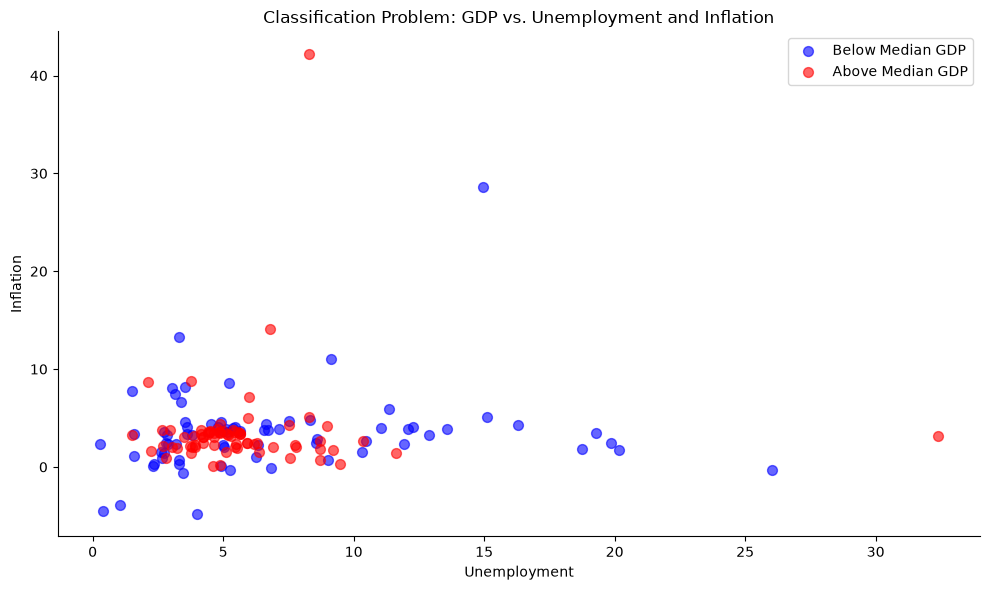

In [56]:
# Eyeball the classification problem (scatter plot)

fig, ax = plt.subplots(figsize=(10, 6))
for label, color, name in [(0, 'blue', 'Below Median GDP'), (1, 'red', 'Above Median GDP')]:
    subset = ds[ds['gdp_binary'] == label]
    ax.scatter(subset['unemployment'], subset['inflation'], c=color, label=name, s=50, alpha=0.6)

ax.set_xlabel('Unemployment')
ax.set_ylabel('Inflation')
ax.set_title('Classification Problem: GDP vs. Unemployment and Inflation')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('classification_problem.png', dpi=300)
ax.legend()
plt.show()

# Feature matrix x and target vector y
X = ds[['unemployment', 'inflation']] 
y = ds['gdp_binary']

The classification scater plot create a visual to show the interaction between countires inflation and Unemployment and how they fall into the binary. the concentration of country above the GDP median value at a value below 15% unemployment shows that country with higer GDP have a lower unemployment and vis a vis. 

In [57]:
# Discriminant Analysis (LDA)
lda = LinearDiscriminantAnalysis()
lda.fit(X, y)

# Add predictions to the dataset
ds['lda_pred'] = lda.predict(X)

# print LDA parameters
print("___ LDA Model Summary ___")
print("print probabilities:", dict(zip(lda.classes_, np.round(lda.priors_, 4))))
print("Group means:", pd.DataFrame(lda.means_, columns=X.columns, index=lda.classes_))
print("Coefficients of linear discriminants:", pd.Series(lda.coef_[0], index=X.columns))

___ LDA Model Summary ___
print probabilities: {np.int64(0): np.float64(0.4966), np.int64(1): np.float64(0.5034)}
Group means:    unemployment  inflation
0      6.904149   3.452520
1      5.774434   3.629678
Coefficients of linear discriminants: unemployment   -0.055688
inflation       0.014086
dtype: float64


LDA Model summary separated two regimes using unemployment as the primary predictor while inflation, the summary result shows that 50.34% of the observation is characterized by lower unemployment vs group 0, stating unemployment have a more discriminatory weight (00.0557) of inflation (0.014). this can be interperted that group 1 have a tighter and higer economic activities which is characterised by the lover uneployment rate. 

In [58]:
# Probit Model
x_probit = sm.add_constant(X)  # Add constant term for intercept
probit = sm.Probit(y, x_probit).fit()

# predict probabilities and classify at 0.5 threshold
pr_l = probit.predict(x_probit)
ds['probit_pred'] = (pr_l >= 0.5).astype(int)

print("___ Probit Model Summary ___")
print(probit.summary())


Optimization terminated successfully.
         Current function value: 0.685018
         Iterations 4
___ Probit Model Summary ___
                          Probit Regression Results                           
Dep. Variable:             gdp_binary   No. Observations:                  147
Model:                         Probit   Df Residuals:                      144
Method:                           MLE   Df Model:                            2
Date:                Fri, 27 Nov 2026   Pseudo R-squ.:                 0.01170
Time:                        12:33:29   Log-Likelihood:                -100.70
converged:                       True   LL-Null:                       -101.89
Covariance Type:            nonrobust   LLR p-value:                    0.3037
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.1954      0.189      1.036      0.300      -0.174       

This probit models the posibility of GDP =1 across 147 countries using unemoloyment and inflation, the result comfirm that neither predictor has a satistically significant effect on the GDP outcome.
                                    THE MODEL FIT               
Pseudo R-squared(0.0117): the model explain on 1.17% of the variation in GDP relative to an intercept-only model, indicating a very weak explanatory power.
LLR p-value(0.3007): The likelihood Ratio Test evaluate whether the model as a whole fits significantly better than the model with no predictors. Because 0.3037>0.05, the overall model is not statistically significant therefore we cant regect the null hypothesis that both slop coefficients are simulaneously zerp

In [66]:
# Support Vector Machine (SVM) Classifier (Linear Kernel, cost = 11)

svmfit = SVC(kernel='linear', C=11, probability=True)
svmfit.fit(X, y)

# Add predictions to the dataset
ds['svm_pred'] = svmfit.predict(X)

print("___ SVM Model Summary ___")
print(f"kernel: {svmfit.kernel}, C: {svmfit.C}")
print(f"Number of support vectors: {svmfit.n_support_.sum()} (per class: {svmfit.n_support_})")
print("svmfit_coef")


___ SVM Model Summary ___
kernel: linear, C: 11
Number of support vectors: 10 (per class: [4 4 2])
svmfit_coef


C:\Users\Admin\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM Model Linear Kernel create an hyperlane boundary between the two economic regimes, directly comparable to the linear boundary in LDA and Probit, and because C is set well above the default(1.0), the optimizer applies a strict penalty for misclassifield observations, pushing hard to narrow the margin and separate the training points rather than the tolerating margin violations. Out of the 147 total observation from the probit output, 138 point line either dirrectly on the margin boundary or on the wrong side of it while we also have a symmetric overlap that shows that even under a strict penalty of c=11 the two group falls right on each other. 


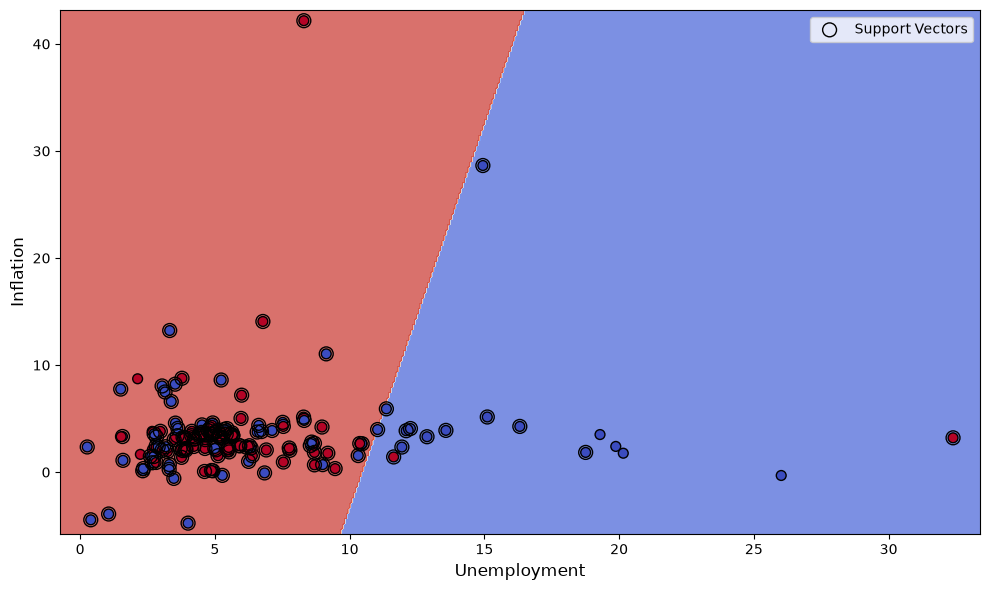

In [60]:
# Plot SVM decision boundary
x_min, x_max = X['unemployment'].min() - 1, X['unemployment'].max() + 1
y_min, y_max = X['inflation'].min() - 1, X['inflation'].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))

grid_df = pd.DataFrame({"unemployment": xx.ravel(), "inflation": yy.ravel()})
z = svmfit.predict(grid_df).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(10, 6))
ax.contourf(xx, yy, z, alpha=0.75, cmap=plt.cm.coolwarm)
ax.scatter(X['unemployment'], X['inflation'], c=y, edgecolors='k', cmap=plt.cm.coolwarm, s=50)

# Highlight support vectors with 'x' markers
ax.scatter(svmfit.support_vectors_[:, 0], svmfit.support_vectors_[:, 1], s=100, facecolors='none', edgecolors='k', label='Support Vectors')
ax.set_xlabel('Unemployment', fontsize=12)
ax.set_ylabel('Inflation', fontsize=12)
ax.legend()
plt.tight_layout()
plt.show()

The SVM plot decision bpundary separating your binary target classes across the unemployment x and the inflation y feature space, directly illustratind the diagnostics from the earlier SVM summary. this plot proves why no striaght line in the unemployment-inflation plan can cleanly separate the high and low GDP economies. While high unemployment economies belong to lower GDP regime (blue), low to moderate unemplyment is shared equally by both high and low GDP COUNTIRES comfirming both labour market and price indicator alone do not determine aggregate economic size. 

<function matplotlib.pyplot.show(close=None, block=None)>

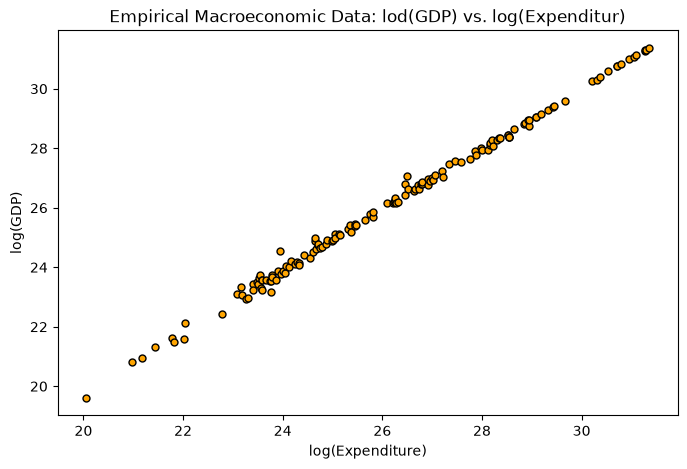

In [61]:
# Sort by log_expenditure for a clean 1D curve plotting
df_clean["log_gdp"] = np.log(df_clean["gdp"])
df_sorted = df_clean.sort_values(by="log_expenditure"). reset_index(drop=True)

x = df_sorted[["log_expenditure"]].values
y = df_sorted["log_gdp"].values

x_test = np.linspace(x.min(), x.max(), 500)[:, np.newaxis]

# Eyeball emperical data
plt.figure(figsize=(8, 5))
plt.scatter(x, y, s=25, edgecolor="black", c="orange", label="2025 Economics")
plt.xlabel("log(Expenditure)")
plt.ylabel("log(GDP)")
plt.title("Empirical Macroeconomic Data: lod(GDP) vs. log(Expenditur)")
plt.legend
plt.show


<function matplotlib.pyplot.show(close=None, block=None)>

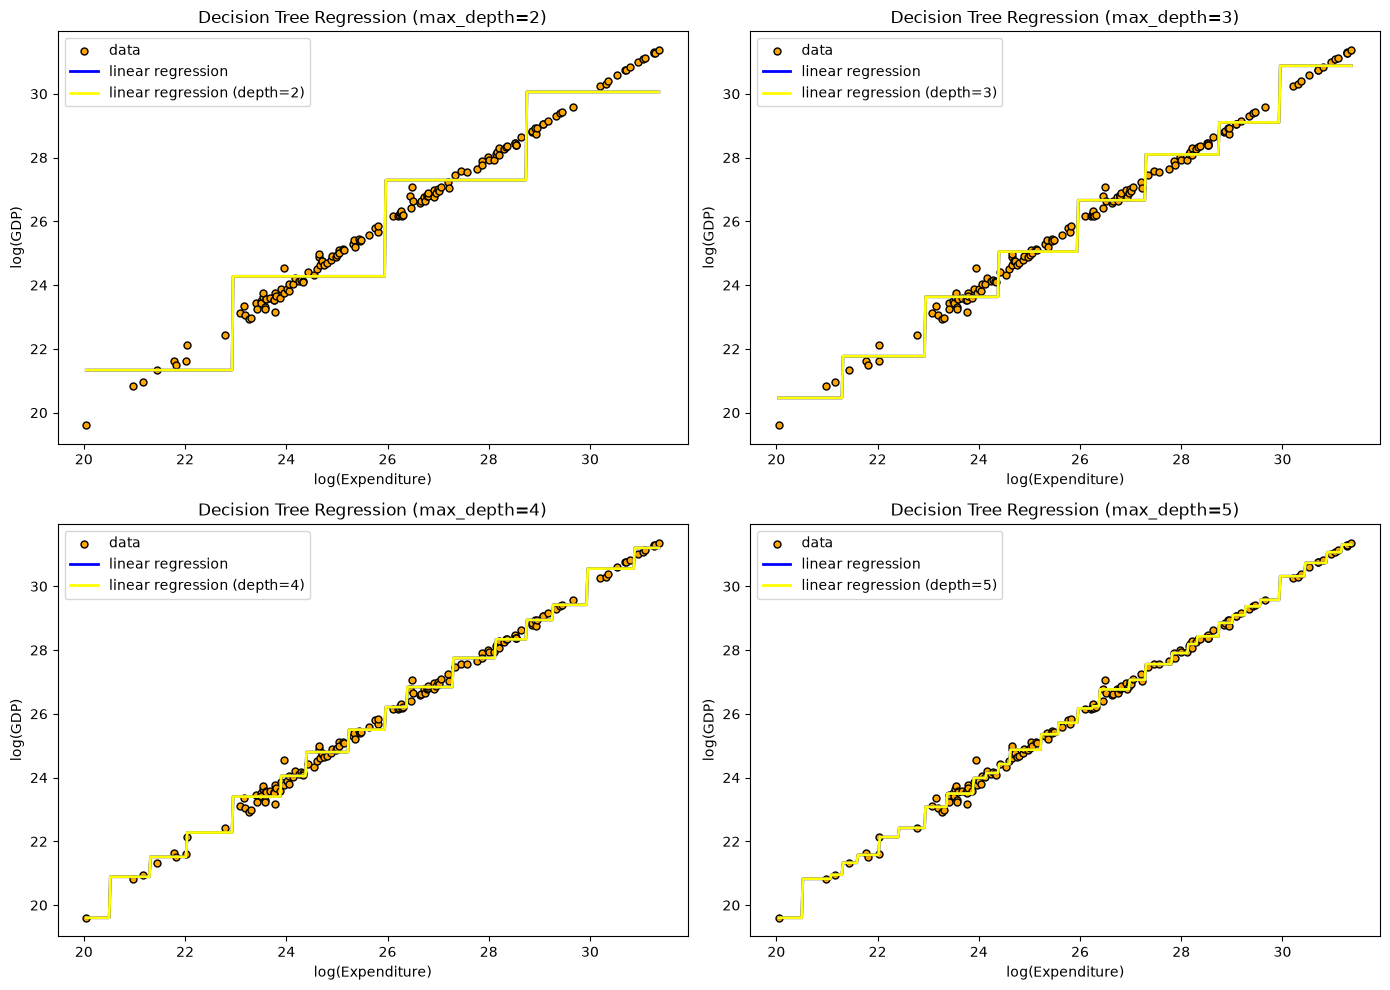

In [62]:
# Linear Rgression vs. Decision Tree Regression 

regr_lin = LinearRegression().fit(x,y)
y_lin = regr_lin.predict(x_test)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
depths = [2, 3, 4, 5]

for ax, depth in zip(axes.ravel(), depths):
    regr_tree = DecisionTreeRegressor(max_depth=depth, random_state=80).fit(x, y)
    y_tree = regr_tree.predict(x_test)

    ax.scatter(x, y, s=25, edgecolor="black", c="orange", label="data")
    ax.plot(x_test, y_tree, color="blue", label="linear regression", linewidth=2)
    ax.plot(x_test, y_tree, color="yellow", label=f"linear regression (depth={depth})", linewidth=2)
    ax.set_xlabel("log(Expenditure)")
    ax.set_ylabel("log(GDP)")
    ax.set_title(f"Decision Tree Regression (max_depth={depth})")
    ax.legend()

plt.tight_layout()
plt.show



These four panels demonstrate the bias–variance trade-off in Decision Tree Regression as tree depth increases from max_depth=2 to max_depth=5 when predicting log⁡("GDP" ) from log⁡("Expenditure" ). While the underlying macroeconomic data follows a tight, continuous linear relationship across the entire range, decision trees approximate this slope using piecewise-constant step functions that assign local sample averages to discrete intervals.
At max_depth=2, the model produces only four coarse plateaus, severely underfitting the data and leaving large prediction errors at both tails. Increasing to max_depth=3 doubles the partitions to eight steps, tracking the central cluster more closely while still flattening at the extremes. At max_depth=4, sixteen fine steps closely hug the linear trajectory without erratic jumps, achieving the best balance. Finally, max_depth=5 introduces thirty-two narrow steps that begin chasing isolated points (notably near x=22.0 and x=23.9), signaling early overfitting to sample noise. 


In [63]:
# Define 3-Class Economic Regime Target
# 0 = Healthy   (Unemployment <= 6% and Inflation <= 5%)
# 1 = Recession (Unemployment > 6% and Inflation <= 5%)
# 2 = Stagflation (Inflation > 5%)

def classify_regime(row):
    if row["inflation"] > 6.0:
        return 2 # Stageflation /High-Inflation Regime
    elif row["unemployment"] > 6.0:
        return 1 # Recession / High labour Slack
    else:
        return 0 # Healthy / Macro Stability

df_clean["regime_code"] = df_clean.apply(classify_regime, axis=1)
regime_names = ["Healthy", "Recession", "Stagflation"]
df_clean["economic_state"] = df_clean["regime_code"].map(dict(enumerate(regime_names)))

features = ["unemployment", "inflation"]
x = df_clean[features]
y = df_clean["regime_code"]

# 70% Train / 30% Test Stratified Split
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.30, stratify=y, random_state=42
)

=== Decision Tree Rules ===
|--- unemployment <= 6.08
|   |--- inflation <= 5.81
|   |   |--- class: 0
|   |--- inflation >  5.81
|   |   |--- class: 2
|--- unemployment >  6.08
|   |--- inflation <= 5.53
|   |   |--- class: 1
|   |--- inflation >  5.53
|   |   |--- class: 2

Decision Tree Test Accuracy: 100.00%
              precision    recall  f1-score   support

     Healthy       1.00      1.00      1.00        27
   Recession       1.00      1.00      1.00        14
 Stagflation       1.00      1.00      1.00         4

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



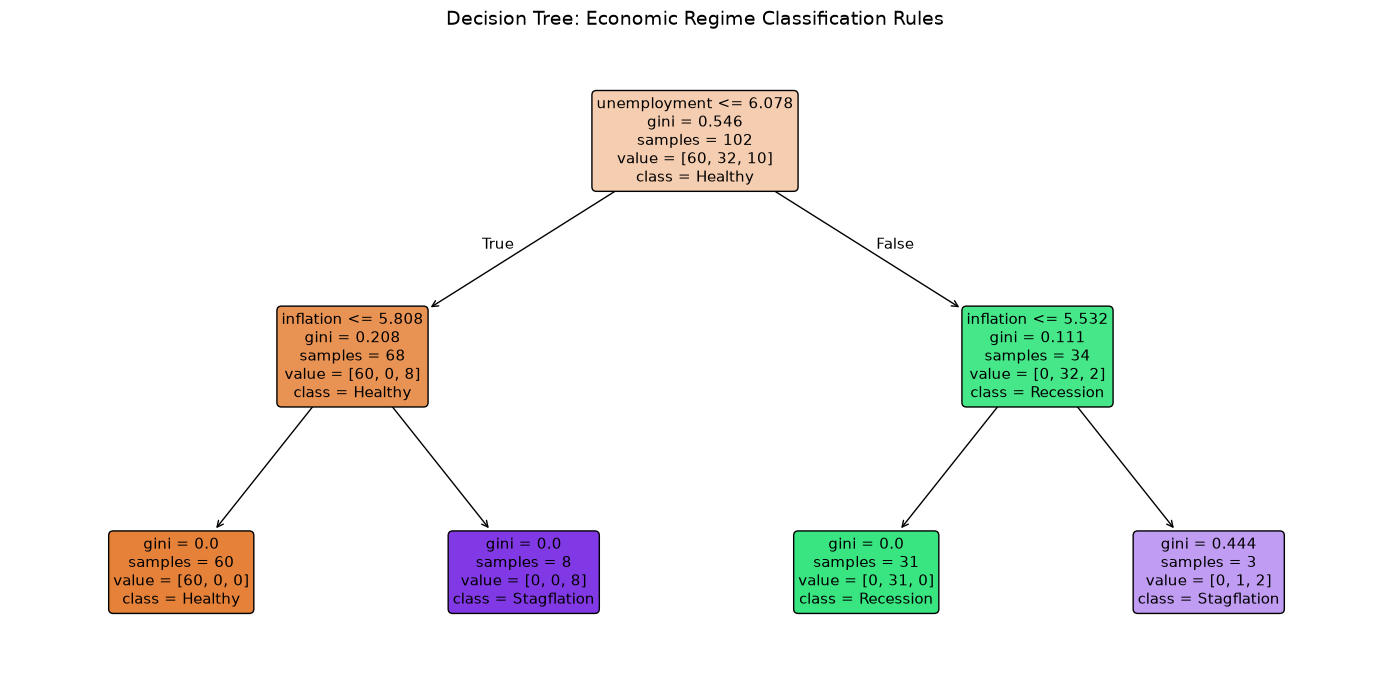

In [64]:
# Decision Tree Classifier
dt_clf = DecisionTreeClassifier(max_depth=3, min_samples_leaf=3, random_state=42)
dt_clf.fit(x_train, y_train)

y_pred_dt = dt_clf.predict(x_test)

print("=== Decision Tree Rules ===")
print(export_text(dt_clf, feature_names=features))
print(f"Decision Tree Test Accuracy: {accuracy_score(y_test, y_pred_dt) * 100:.2f}%")
print(classification_report(y_test, y_pred_dt, target_names=regime_names))

# Visualize the Decision Tree Structure
plt.figure(figsize=(14, 7))
plot_tree(
    dt_clf,
    feature_names=features,
    class_names=regime_names,
    filled=True,
    rounded=True,
    fontsize=11
)
plt.title("Decision Tree: Economic Regime Classification Rules", fontsize=14)
plt.tight_layout()
plt.show()

The Decision Tree achieves 100.00% test accuracy across 45 observations by partitioning economic regimes using clear macroeconomic thresholds. It splits first at 6.08% unemployment and then near 5.53%–5.81% inflation: low unemployment and low inflation define Healthy regimes (Class 0), higher unemployment with low inflation defines Recession (Class 1), and inflation above ~5.5%–5.8% isolates Stagflation (Class 2)